# Tokenizer Analysis on Synthetic MRI Captions
**TRM Assignment 1B artefact — Hugging Face LLM Course, Chapter 6 (🤗 Tokenizers library)**

**Question:** how do general, CLIP and biomedical tokenizers split the clinical terms in my synthetic MRI captions, and what does that imply for the text encoder in my contrastive VLM?

**Chapter 6 concepts applied:** fast tokenizers, offset mapping, subword algorithms (WordPiece vs BPE), training a new tokenizer from an existing one (`train_new_from_iterator`).

In [1]:
!pip install -q transformers pandas matplotlib

## 1. Generate synthetic captions from structured metadata
Mirrors my project's approach: captions built from metadata fields (diagnosis, age, sex, CDR) rather than radiology reports.

In [2]:
import random
import pandas as pd

random.seed(42)

diagnoses = {
    "cognitively normal": "no evidence of hippocampal atrophy",
    "very mild dementia": "mild hippocampal atrophy and ventriculomegaly",
    "mild dementia": "moderate hippocampal atrophy with enlarged lateral ventricles",
    "moderate dementia": "marked medial temporal lobe atrophy and periventricular hyperintensities",
}
cdr = {"cognitively normal": 0.0, "very mild dementia": 0.5, "mild dementia": 1.0, "moderate dementia": 2.0}
templates = [
    "T1-weighted brain MRI of a {age}-year-old {sex} with {dx} (CDR {cdr}), showing {finding}.",
    "Axial MRI, {sex}, age {age}: {dx}; {finding}.",
    "Brain MRI consistent with {dx} in a {age}-year-old {sex}. Findings: {finding}.",
]

rows = []
for _ in range(60):
    dx = random.choice(list(diagnoses))
    rows.append({
        "diagnosis": dx,
        "caption": random.choice(templates).format(
            age=random.randint(60, 90), sex=random.choice(["male", "female"]),
            dx=dx, cdr=cdr[dx], finding=diagnoses[dx]),
    })
df = pd.DataFrame(rows)
captions = df["caption"].tolist()
df.head()

,diagnosis,caption
0,cognitively normal,T1-weighted brain MRI of a 83-year-old female ...
1,very mild dementia,T1-weighted brain MRI of a 64-year-old male wi...
2,cognitively normal,Brain MRI consistent with cognitively normal i...
3,cognitively normal,T1-weighted brain MRI of a 66-year-old male wi...
4,cognitively normal,Brain MRI consistent with cognitively normal i...


## 2. Load tokenizers
- **BERT** (general English, WordPiece)
- **CLIP** text tokenizer (BPE) — the default text encoder for a CLIP-style VLM
- **BiomedBERT / PubMedBERT** (WordPiece with a vocabulary built from PubMed text)

In [3]:
from transformers import AutoTokenizer

tok_names = {
    "BERT (general)": "bert-base-uncased",
    "CLIP (text)": "openai/clip-vit-base-patch32",
    "BiomedBERT": "microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract-fulltext",
}
tokenizers = {k: AutoTokenizer.from_pretrained(v) for k, v in tok_names.items()}
for k, t in tokenizers.items():
    print(f"{k:16} fast={t.is_fast}  vocab={t.vocab_size:,}  max_len={t.model_max_length}")

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

...

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/28.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/226k [00:00<?, ?B/s]

BERT (general)   fast=True  vocab=30,522  max_len=512
CLIP (text)      fast=True  vocab=49,408  max_len=77
BiomedBERT       fast=True  vocab=30,522  max_len=1000000000000000019884624838656


## 3. How are key clinical terms split?

In [4]:
terms = ["hippocampal", "atrophy", "ventriculomegaly", "periventricular",
         "hyperintensities", "dementia", "T1-weighted", "medial temporal lobe"]

rows = []
for term in terms:
    row = {"term": term}
    for k, t in tokenizers.items():
        pieces = t.tokenize(term)
        row[k] = f"{len(pieces)}: {' | '.join(pieces)}"
    rows.append(row)
pd.set_option("display.max_colwidth", None)
pd.DataFrame(rows)

,term,BERT (general),CLIP (text),BiomedBERT
0,hippocampal,4: hip | ##po | ##camp | ##al,3: hippo | camp | al</w>,1: hippocampal
1,atrophy,3: at | ##rop | ##hy,2: atro | phy</w>,1: atrophy
2,ventriculomegaly,6: vent | ##ric | ##ulo | ##me | ##gal | ##y,6: ven | tric | ul | ome | gal | y</w>,3: ventr | ##icul | ##omegaly
3,periventricular,5: per | ##ive | ##nt | ##ric | ##ular,4: peri | ven | tric | ular</w>,2: periv | ##entricular
4,hyperintensities,4: hyper | ##int | ##ens | ##ities,4: hyper | inten | s | ities</w>,2: hyperint | ##ensities
5,dementia,1: dementia,1: dementia</w>,1: dementia
6,T1-weighted,4: t | ##1 | - | weighted,4: t</w> | 1</w> | -</w> | weighted</w>,3: t1 | - | weighted
7,medial temporal lobe,3: medial | temporal | lobe,4: medi | al</w> | temporal</w> | lobe</w>,3: medial | temporal | lobe


## 4. Tokens per caption and CLIP's 77-token limit

,mean,min,max,over_77 (CLIP limit)
BERT (general),35.6,25.0,45.0,0
CLIP (text),34.9,25.0,43.0,0
BiomedBERT,27.9,19.0,35.0,0


/tmp/ipykernel_1529/3483077997.py:9: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(lengths.values(), labels=lengths.keys())


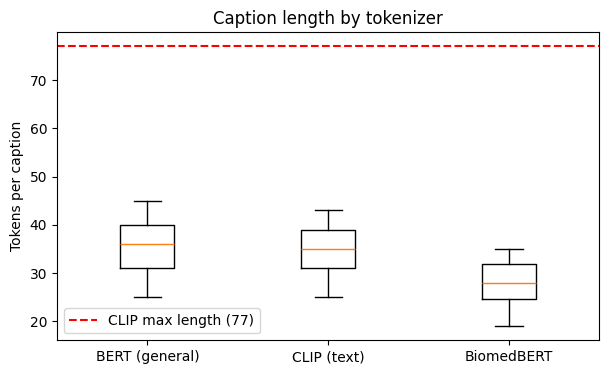

In [5]:
import matplotlib.pyplot as plt

lengths = {k: [len(t(c)["input_ids"]) for c in captions] for k, t in tokenizers.items()}
summary = pd.DataFrame({k: pd.Series(v).describe()[["mean", "min", "max"]] for k, v in lengths.items()}).T.round(1)
summary["over_77 (CLIP limit)"] = [sum(l > 77 for l in v) for v in lengths.values()]
display(summary)

plt.figure(figsize=(7, 4))
plt.boxplot(lengths.values(), labels=lengths.keys())
plt.axhline(77, ls="--", c="red", label="CLIP max length (77)")
plt.ylabel("Tokens per caption"); plt.title("Caption length by tokenizer"); plt.legend()
plt.show()

## 5. Offset mapping: where does each token come from?
Fast tokenizers return character offsets for every token (Chapter 6.3). Useful later for checking which caption words a model attends to.

In [6]:
sample = captions[0]
print(sample, "\n")
for k, t in tokenizers.items():
    enc = t(sample, return_offsets_mapping=True, add_special_tokens=False)
    spans = [sample[s:e] for s, e in enc["offset_mapping"]]
    print(f"{k}:\n  {spans[:20]}\n")

T1-weighted brain MRI of a 83-year-old female with cognitively normal (CDR 0.0), showing no evidence of hippocampal atrophy. 

BERT (general):
  ['T', '1', '-', 'weighted', 'brain', 'MRI', 'of', 'a', '83', '-', 'year', '-', 'old', 'female', 'with', 'cognitive', 'ly', 'normal', '(', 'CD']

CLIP (text):
  ['T', '1', '-', 'weighted', 'brain', 'MRI', 'of', 'a', '8', '3', '-', 'year', '-', 'old', 'female', 'with', 'cogn', 'iti', 'vely', 'normal']

BiomedBERT:
  ['T1', '-', 'weighted', 'brain', 'MRI', 'of', 'a', '83', '-', 'year', '-', 'old', 'female', 'with', 'cognitively', 'normal', '(', 'CDR', '0', '.']



## 6. Train a new tokenizer on my caption corpus
`train_new_from_iterator` (Chapter 6.2) keeps BERT's algorithm but learns a vocabulary from my captions. Note: with templated captions this will trivially learn whole words — the point is to see the *ceiling* on fragmentation, not to use this tokenizer in the model.

In [7]:
def batch_iterator(bs=16):
    for i in range(0, len(captions), bs):
        yield captions[i:i + bs]

caption_tok = tokenizers["BERT (general)"].train_new_from_iterator(batch_iterator(), vocab_size=500)
for term in ["hippocampal", "ventriculomegaly", "periventricular", "hyperintensities"]:
    print(f"{term:18} general: {tokenizers['BERT (general)'].tokenize(term)}  ->  caption-trained: {caption_tok.tokenize(term)}")

hippocampal        general: ['hip', '##po', '##camp', '##al']  ->  caption-trained: ['hippocampal']
ventriculomegaly   general: ['vent', '##ric', '##ulo', '##me', '##gal', '##y']  ->  caption-trained: ['ventriculomegaly']
periventricular    general: ['per', '##ive', '##nt', '##ric', '##ular']  ->  caption-trained: ['periventricular']
hyperintensities   general: ['hyper', '##int', '##ens', '##ities']  ->  caption-trained: ['hyperintensities']


## 7. Findings and implications for my research

- **Fragmentation:** which tokenizer split the clinical terms most, and by how much?
  - Across the five clinical terms, the total token counts are: BERT = 22, CLIP = 19, and BiomedBERT = 9
  - BiomedBERT keeps “hippocampal” and “atrophy” whole. Where it does split, the pieces are close to real morphemes.
  - CLIP’s splits mostly don’t follow morpheme boundaries and it breaks common words like "cognitively" and splits numbers into single digits.
- **Length:** do any captions approach CLIP's 77-token limit? Does template choice matter?
  - No caption was close to CLIP's 77 token limit, with the largest being 43, so truncation wasn't a problem.
  - The mean tokens per caption were: BERT = 35.6, CLIP = 34.9, and BiomedBERT = 27.9.
  - The token spread between 19–45 likely came from which template was used and how long the finding text is, with the CDR template having the longest.
- **Decision:** what does this mean for my text encoder choice (CLIP default vs BiomedBERT) and the planned ablation?
  - For a CLIP-style VLM, the default CLIP text encoder fragments the exact terms that separate the diagnostic classes. This supports comparing the default CLIP text encoder against a domain text encoder, and is part of why my final design uses BiomedCLIP as the primary initialisation with a general OpenCLIP checkpoint as a secondary check. Fragmentation alone doesn’t prove worse performance, so the comparison has to test it.
- **Limitation:** synthetic, templated captions have a small vocabulary — how might results differ on real radiology text?
  - The captions used come from 3 templates and 4 findings, so the vocabulary is tiny and the comparison rests on only a handful of terms.
  - Real radiology reports are longer, which could push past 77 tokens and make CLIP truncation a real issue. They also have abbreviations, negation, measurements and inconsistent phrasing, so the fragmentation and length results may not hold.